# JC 主线：统一评估与误差分析
本 Notebook 只做 2024 年开发折比较，不读 2025 目标。一次性统一重训经典模型和 PyTorch 模型，确保排行榜采用每折共同时间戳。
天气与假日分组是事后误差诊断；目标小时天气不会进入特征。

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.jc_stage4 import run_stage4
metadata = run_stage4()
print(metadata)

  fold                     model    n       MAE      RMSE       R2
fold_1         linear_regression 2208 26.887436 40.328345 0.881175
fold_1             random_forest 2208 20.279441 32.483647 0.922907
fold_1       naive_previous_hour 2208 45.820199 65.689415 0.684735
fold_1       naive_previous_week 2208 32.034873 53.337620 0.792149
fold_1 linear_regression_weather 2208 29.342594 40.740267 0.878736
fold_1     random_forest_weather 2208 20.962048 33.353755 0.918722
fold_1                       mlp 2208 21.672763 31.848154 0.925894
fold_1                 lstm_168h 2208 20.259190 30.741902 0.930953
fold_2         linear_regression 2039 22.111679 32.699586 0.903536
fold_2             random_forest 2039 15.112219 23.465594 0.950324
fold_2       naive_previous_hour 2039 35.771457 55.581592 0.721295
fold_2       naive_previous_week 2039 30.390878 49.466725 0.779246
fold_2 linear_regression_weather 2039 22.062947 31.565979 0.910108
fold_2     random_forest_weather 2039 15.698357 23.918600 0.94

## 同时间戳模型比较
各模型在每个开发折相同的有效目标时刻评分。MAE、RMSE、R²来自模型预测，不把特征缺失造成的样本差异混入排行榜。

,fold,model,n,MAE,RMSE,R2
7,fold_1,lstm_168h,2208,20.259190,30.741902,0.930953
1,fold_1,random_forest,2208,20.279441,32.483647,0.922907
5,fold_1,random_forest_weather,2208,20.962048,33.353755,0.918722
6,fold_1,mlp,2208,21.672763,31.848154,0.925894
0,fold_1,linear_regression,2208,26.887436,40.328345,0.881175
4,fold_1,linear_regression_weather,2208,29.342594,40.740267,0.878736
3,fold_1,naive_previous_week,2208,32.034873,53.337620,0.792149
2,fold_1,naive_previous_hour,2208,45.820199,65.689415,0.684735
9,fold_2,random_forest,2039,15.112219,23.465594,0.950324
13,fold_2,random_forest_weather,2039,15.698357,23.918600,0.948388


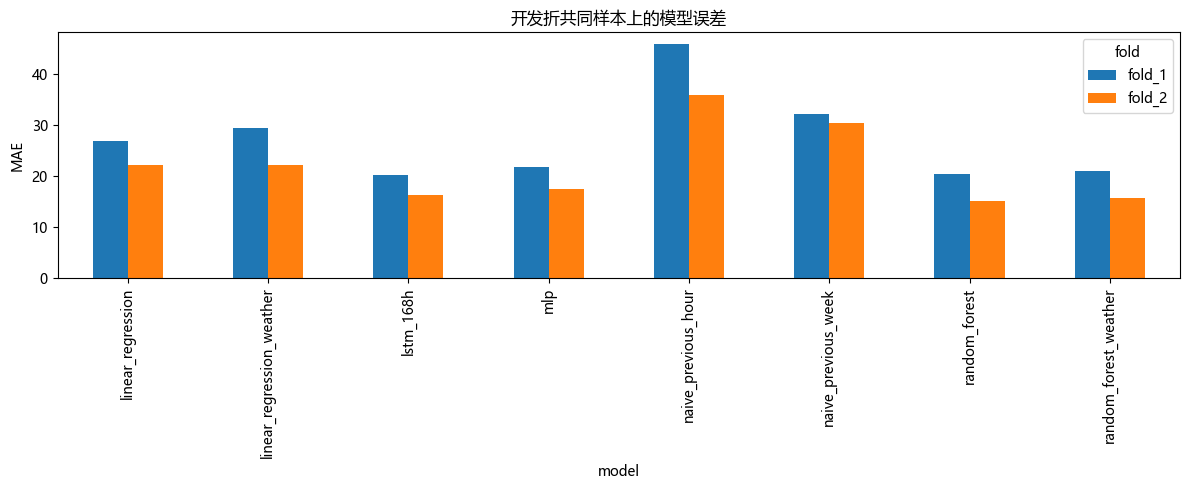

In [2]:
comparison = pd.read_csv(ROOT / 'results/metrics/jc_unified_comparison.csv')
display(comparison.sort_values(['fold','MAE']))
ax = comparison.pivot(index='model', columns='fold', values='MAE').plot.bar(figsize=(12,5))
ax.set_ylabel('MAE'); ax.set_title('开发折共同样本上的模型误差'); plt.tight_layout()
plt.savefig(ROOT / 'results/figures/jc_unified_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 特征组消融
随机森林每种特征组合独立拟合；四组只在共同验证时刻评分，训练行数可能因历史特征缺失略有差异。

,fold,feature_set,features,train_rows,n,MAE,RMSE,R2
0,fold_1,calendar,10,4366,2208,33.758373,52.199313,0.800926
1,fold_1,calendar+demand,21,4199,2208,20.279441,32.483647,0.922907
2,fold_1,calendar+weather,34,4199,2208,27.567944,42.310083,0.869210
3,fold_1,calendar+demand+weather,45,4199,2208,20.962048,33.353755,0.918722
4,fold_2,calendar,10,6574,2039,49.553436,80.397941,0.416860
5,fold_2,calendar+demand,21,6407,2039,15.112219,23.465594,0.950324
6,fold_2,calendar+weather,34,6407,2039,24.532185,36.658141,0.878766
7,fold_2,calendar+demand+weather,45,6407,2039,15.698357,23.918600,0.948388


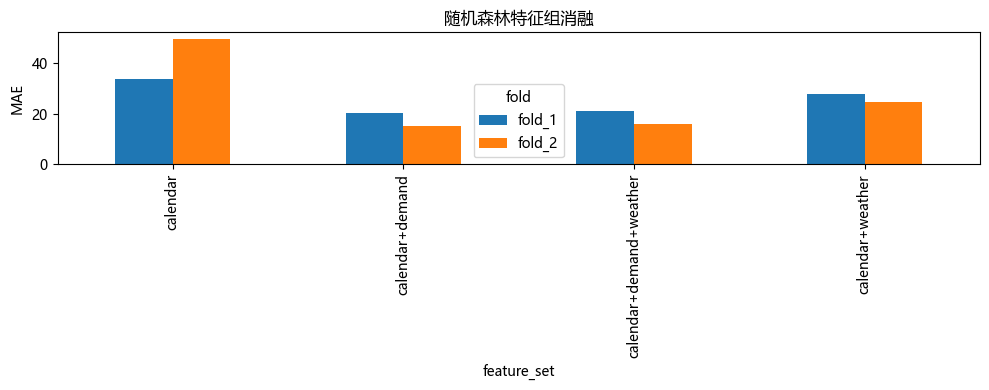

In [3]:
ablation = pd.read_csv(ROOT / 'results/metrics/jc_rf_feature_ablation.csv')
display(ablation[['fold','feature_set','features','train_rows','n','MAE','RMSE','R2']])
ax = ablation.pivot(index='feature_set', columns='fold', values='MAE').plot.bar(figsize=(10,4))
ax.set_ylabel('MAE'); ax.set_title('随机森林特征组消融'); plt.tight_layout()
plt.savefig(ROOT / 'results/figures/jc_feature_ablation.png', dpi=150, bbox_inches='tight')
plt.show()

## 误差切片
天气分组按目标小时历史天气产品中的降水是否大于 0 描述，只用于事后诊断；它不是预测时可用的目标天气。假日按美国联邦假日日历识别，且报告每组样本量。

In [4]:
errors = pd.read_csv(ROOT / 'results/metrics/jc_development_error_analysis.csv')
display(errors[errors['model'].isin(['random_forest','lstm_168h'])].sort_values(['fold','model','group','category']))
holiday = errors[(errors.group == 'us_federal_holiday') & errors.model.isin(['random_forest','lstm_168h'])]
display(holiday)

,fold,model,group,category,n,MAE,RMSE
79,fold_1,lstm_168h,hour_period,day_10_15,552,21.655210,29.984798
80,fold_1,lstm_168h,hour_period,evening_16_19,368,34.534416,46.215051
81,fold_1,lstm_168h,hour_period,late_20_23,368,18.909387,28.430803
78,fold_1,lstm_168h,hour_period,morning_06_09,368,24.000120,34.446187
77,fold_1,lstm_168h,hour_period,night_00_05,552,7.752269,11.286391
86,fold_1,lstm_168h,target_weather,no_precipitation,1873,19.085469,28.046927
87,fold_1,lstm_168h,target_weather,precipitation,335,26.821516,42.788768
84,fold_1,lstm_168h,us_federal_holiday,holiday,48,35.368056,55.969724
85,fold_1,lstm_168h,us_federal_holiday,non_holiday,2160,19.923437,29.940816
82,fold_1,lstm_168h,weekend,weekday,1584,20.094375,31.122029


,fold,model,group,category,n,MAE,RMSE
18,fold_1,random_forest,us_federal_holiday,holiday,48,31.089209,57.904128
19,fold_1,random_forest,us_federal_holiday,non_holiday,2160,20.039223,31.687968
84,fold_1,lstm_168h,us_federal_holiday,holiday,48,35.368056,55.969724
85,fold_1,lstm_168h,us_federal_holiday,non_holiday,2160,19.923437,29.940816
106,fold_2,random_forest,us_federal_holiday,holiday,96,17.494795,25.927234
107,fold_2,random_forest,us_federal_holiday,non_holiday,1943,14.994500,23.337238
172,fold_2,lstm_168h,us_federal_holiday,holiday,96,21.626894,27.813286
173,fold_2,lstm_168h,us_federal_holiday,non_holiday,1943,15.951606,23.554354
